# 05 · Robust: does the model survive messy Hinglish spelling? (Experiment 2)

Romanised Hindi has no standard spelling: *bahut / bohot / bht*, *nahi / nhi*, *accha / acha*. A model that learned one spelling may fail on another.

**Test:** respell the Hindi words in the **test** tweets and measure how much F1 drops. The label never changes, only the spelling.

| Noise | How | Why |
|---|---|---|
| **natural** | swap a word for another spelling of it that real users wrote in the *train* set | the variation the model will meet in practice |
| **rule** | SMS-style edits: drop inner vowels, stretch/shorten a vowel, w↔v, z↔j, ph↔f … | spellings that may never appear in the data |

Each at **3 levels**: 25 %, 50 % and 100 % of eligible Hindi words respelled.

**Fix tested:** *spelling augmentation*. HingBERT is retrained with half of the training tweets respelled using **natural variants mined from train only**. The training set has the same size, so compute is unchanged. The **rule** noise was never used in training, so it tests whether the robustness carries over to unseen kinds of misspelling.

**Target (from the plan):** a smaller F1 drop than the plain model, with little or no loss on clean tweets.

Code: `src/hinglish/robust.py`. GPU needed only for section 4 (5 HingBERT runs, about 40 min on the M4 Pro; finished runs are skipped).

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from scipy.special import softmax
from sklearn.metrics import f1_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG_DIR = ROOT / "results/figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
RUNS, RROB = ROOT / "runs", ROOT / "runs_robust"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from hinglish.data import load_splits, LABELS
from hinglish import train
from hinglish.train import TrainConfig, run_finetune, make_loader, predict_logits, get_device
from hinglish.calibration import ece_score, fit_temperature, apply_temperature
from hinglish.robust import english_vocab, mine_variants, perturb, augment_train

S = load_splits(ROOT / "data/processed")
CFG = TrainConfig()            # identical settings to notebook 03
if (ROOT / "models_hf/hingbert/.done").exists():      # local copy downloaded in notebook 03's session
    train.MODELS["hingbert"] = str(ROOT / "models_hf/hingbert")
NAMES = {"tfidf_lr": "TF-IDF + LR", "tfidf_lr_aug": "TF-IDF + LR (aug)", "mbert": "mBERT", "xlmr": "XLM-R",
         "muril": "MuRIL", "hingbert": "HingBERT", "hingbert_aug": "HingBERT (aug)"}

/Users/rahullalwani/Documents/IITMandi/Sem1/NLP/Project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Real spelling variants, mined from the training tweets

Words are grouped by consonant skeleton (*bahut, bohot, bht → b-h-t*). A pair counts as a variant only if it differs in the ways people actually respell Hinglish: repeated letters, dropped inner vowels, a few vowel swaps in longer words, w/v, z/j, ph/f. A short block list stops swaps between different words that look alike (*bhai/bhi, kya/kiya*).

Only Hindi-tagged words are touched. Words the tagger more often marks as English, @mentions, hashtags, names and words under 3 letters are skipped.

In [2]:
eng = english_vocab(S["train"])
V = mine_variants(S["train"], eng)       # TRAIN only: no test information leaks into augmentation
print(f"{len(V)} Hindi words have at least one real alternative spelling in train")
show = ["bahut", "nahi", "accha", "kuch", "mujhe", "zindagi", "pata", "lekin", "chahiye", "sath", "abhi", "gaya"]
pd.DataFrame({"word": show, "variants seen in train": [", ".join(V.get(w, [])[:6]) or "-" for w in show]})

2632 Hindi words have at least one real alternative spelling in train


,word,variants seen in train
0,bahut,"bhut, bohot, bahot, bht, bahoot, bohut"
1,nahi,"nhi, nahii, nhii, nhiii"
2,accha,"acha, achha, aacha"
3,kuch,"kuchh, kucch"
4,mujhe,mjhe
5,zindagi,zindgi
6,pata,"pta, patta, paata, ptaa"
7,lekin,"lakin, lkn"
8,chahiye,"chahye, chaheye"
9,sath,"saath, sth"


## 2. Build the respelled test sets

Fixed seed, so every model sees exactly the same respelled tweets.

In [3]:
te = S["test"]
TEST_SETS = {"clean": te}
for mode in ["natural", "rule"]:
    for p in [0.25, 0.5, 1.0]:
        TEST_SETS[f"{mode} {int(p * 100)}%"] = perturb(te, p, mode, V, eng, seed=2025)

stats = pd.DataFrame({k: {"tweets changed": (d.text != te.text).mean(),
                          "words respelled / tweet": d.n_respelled.mean() if "n_respelled" in d else 0.0}
                      for k, d in TEST_SETS.items()}).T
display(stats.round(3))
print("Eligible Hindi words per tweet:", round(TEST_SETS["natural 100%"].n_eligible.mean(), 2),
      "| tweets with no eligible word stay unchanged at every level")

,tweets changed,words respelled / tweet
clean,0.000,0.000
natural 25%,0.637,1.460
natural 50%,0.751,2.926
natural 100%,0.821,5.799
rule 25%,0.625,1.468
rule 50%,0.738,2.920
rule 100%,0.821,5.783


Eligible Hindi words per tweet: 5.81 | tweets with no eligible word stay unchanged at every level


In [4]:
pd.set_option("display.max_colwidth", 120)
ex = [5, 11, 40]
rows = []
for i in ex:
    for k in ["clean", "natural 50%", "rule 50%", "natural 100%"]:
        rows.append({"tweet": i, "set": k, "text": TEST_SETS[k].text.iloc[i]})
pd.DataFrame(rows).set_index(["tweet", "set"])

text
tweet set                                                                                                                                  
5     clean                                @user #HNY2 ki announcement hogyi to humka iss gola me nhi rehna hum nikal jaounga dusre gola me
      natural 50%                      @user #HNY2 ki announcement hogyi to humka iiss golaa me nhi rehna hum nikal jaounga doosre golaa me
      rule 50%                            @user #HNY2 ki announcement hogyi to humka iiss goola me nhii rehna hum nkal jaounga dusre gla me
      natural 100%                    @user #HNY2 ki announcement hogyi to huumka iiss golaa me nhiii rhna huum nikaal jounga dusare gla me
11    clean                              RT @user @user @user @user @user suar tere jaiso ko sikhaya ja hi nahi sakta kyonki tu suar hai kh
      natural 50%                       RT @user @user @user @user @user suar tre jaiso ko skhaya ja hi nhiii sakta kyonki tu suuar haii kh
      rule 50%                            RT @user @user @user @user @user sar tere jaiso ko skhaya ja hi nahi sakta kyoonki tu sur haii kh
      natural 100%                       RT @user @user @user @user @user sar teree jaso ko sikhaaya ja hi nahii skta kyunki tu sar haii kh
40    clean         RT @user @user corruption ki complain pe aap dhayan Kyu nahi dete ? Mene 2 baar tweet kiya ki jalor Police ( Ahore ) fr
      natural 50%       RT @user @user corruption ki complai pe app dhayan Kyu nhi dte ? Mene 2 bar tweeet kiya ki jalr Police ( Ahore ) fr
      rule 50%         RT @user @user corruption ki complan pe ap dhayan Kyu nahi dete ? Mene 2 baar twet kiya ki jalor Police ( Ahore ) fr
      natural 100%  RT @user @user corruption ki complaain pe aaap dhyan Kyu nahii detee ? Mene 2 baaar tweeet kiyaa ki jaalor Police ( ...

## 3. TF-IDF baseline: plain and augmented

Refitted with the `C` chosen in notebook 02. Character n-grams already share pieces across spellings (*bahut / bohot* share *b*, *h*, *t*), so the baseline may be naturally robust.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, make_union

C = json.loads((ROOT / "results/02_baseline_tfidf.json").read_text())["best_C"]
def tfidf():
    feats = make_union(
        TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True, lowercase=True),
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, lowercase=True, max_features=200_000))
    return make_pipeline(feats, LogisticRegression(C=C, max_iter=3000))

tr_aug = augment_train(S["train"], V, eng, seed=0)
print(f"augmented train: {(tr_aug.text != S['train'].text).mean():.0%} of tweets respelled, same size ({len(tr_aug)})")

LOGITS = {}   # (system, seed) -> {"val": ..., set: logits}
for key, tr in [("tfidf_lr", S["train"]), ("tfidf_lr_aug", tr_aug)]:
    m = tfidf().fit(tr.text, tr.label_id)
    LOGITS[(key, 0)] = {"val": m.decision_function(S["val"].text),
                        **{k: m.decision_function(d.text) for k, d in TEST_SETS.items()}}
    print(key, "clean test wF1", round(f1_score(te.label_id, LOGITS[(key, 0)]["clean"].argmax(1), average="weighted"), 4))

augmented train: 32% of tweets respelled, same size (14000)


tfidf_lr clean test wF1 0.6872


tfidf_lr_aug clean test wF1 0.6848


## 4. Train HingBERT with spelling augmentation (GPU, ~40 min; skipped if done)

* **aug**: 3 seeds, half of the train tweets respelled with natural variants (a random level per tweet), with a fresh draw per seed.
* **plain**: notebook 03 kept only the best seed's checkpoint (seed 43), so seeds 42 and 44 are retrained here with identical settings, giving a fair 3-vs-3 comparison.

Model selection still uses the **clean** validation set, so neither model sees respelled test data.

In [6]:
for kind, seed in [("aug", 42), ("aug", 43), ("aug", 44), ("plain", 42), ("plain", 44)]:
    splits = dict(S)
    if kind == "aug":
        splits["train"] = augment_train(S["train"], V, eng, seed=seed)
    run_finetune("hingbert", seed, splits, RROB / kind, CFG, save_model=True)

[skip] hingbert seed42 already done
[skip] hingbert seed43 already done


[skip] hingbert seed44 already done
[skip] hingbert seed42 already done
[skip] hingbert seed44 already done


## 5. Score every model on clean + 6 respelled test sets

Transformers: the kept checkpoint of mBERT, XLM-R and MuRIL from notebook 03, plus all 3 seeds of plain and augmented HingBERT. Scores are cached in `runs_robust/eval/`.

In [7]:
def checkpoints():
    out = []
    for m in ["mbert", "xlmr", "muril"]:
        out += [(m, int(d.parent.name[4:]), d) for d in sorted((RUNS / m).glob("seed*/model"))]
    plain = {int(d.parent.name[4:]): d for d in (RUNS / "hingbert").glob("seed*/model")}
    plain.update({int(d.parent.name[4:]): d for d in (RROB / "plain/hingbert").glob("seed*/model")})
    out += [("hingbert", s, d) for s, d in sorted(plain.items())]
    out += [("hingbert_aug", int(d.parent.name[4:]), d) for d in sorted((RROB / "aug/hingbert").glob("seed*/model"))]
    return out

from transformers import AutoTokenizer, AutoModelForSequenceClassification
device = get_device()
EVAL = RROB / "eval"; EVAL.mkdir(parents=True, exist_ok=True)
for key, seed, d in checkpoints():
    cache = EVAL / f"{key}_seed{seed}.npz"
    if not cache.exists():
        tok = AutoTokenizer.from_pretrained(d)
        model = AutoModelForSequenceClassification.from_pretrained(d).to(device).eval()
        z = {"val": np.load(d.parent / "logits.npz")["val"]}
        for k, df in TEST_SETS.items():
            z[k] = predict_logits(model, make_loader(tok, df.text, df.label_id, CFG.max_len, CFG.eval_batch_size, False), device)
        np.savez_compressed(cache, **z)
        del model
    z = np.load(cache)
    LOGITS[(key, seed)] = {k: z[k] for k in z.files}
    print(f"{key:13} seed{seed}: clean wF1 {f1_score(te.label_id, LOGITS[(key, seed)]['clean'].argmax(1), average='weighted'):.4f}")

mbert         seed43: clean wF1 0.6877
xlmr          seed43: clean wF1 0.7067


muril         seed44: clean wF1 0.7046
hingbert      seed42: clean wF1 0.7120
hingbert      seed43: clean wF1 0.7157
hingbert      seed44: clean wF1 0.7104
hingbert_aug  seed42: clean wF1 0.7226
hingbert_aug  seed43: clean wF1 0.7210
hingbert_aug  seed44: clean wF1 0.7340


## 6. Results: F1 under respelling

In [8]:
y, yv = te.label_id.values, S["val"].label_id.values
SETS = list(TEST_SETS)
rows = []
for (key, seed), L in LOGITS.items():
    T = fit_temperature(L["val"], yv)
    for k in SETS:
        p = softmax(L[k], axis=1)
        rows.append({"model": key, "seed": seed, "set": k,
                     "wF1": f1_score(y, L[k].argmax(1), average="weighted"),
                     "ECE": ece_score(p, y), "ECE after T": ece_score(apply_temperature(L[k], T), y)})
res = pd.DataFrame(rows)
order = [m for m in NAMES if m in set(res.model)]

f1 = res.groupby(["model", "set"]).wF1.mean().unstack()[SETS].loc[order]
drop = (f1[SETS[1:]].sub(f1["clean"], axis=0) * 100)
f1.index = drop.index = [NAMES[m] for m in order]
print("Weighted F1 (mean over seeds)"); display(f1.round(4))
print("Change vs clean, in F1 points (negative = worse)"); display(drop.round(2))

Weighted F1 (mean over seeds)


set,clean,natural 25%,natural 50%,natural 100%,rule 25%,rule 50%,rule 100%
TF-IDF + LR,0.6872,0.6804,0.6736,0.6645,0.6855,0.6789,0.6544
TF-IDF + LR (aug),0.6848,0.6839,0.6792,0.6753,0.6830,0.6835,0.6705
mBERT,0.6877,0.6862,0.6777,0.6663,0.6810,0.6678,0.6559
XLM-R,0.7067,0.7006,0.6967,0.6835,0.7006,0.7001,0.6681
MuRIL,0.7046,0.7000,0.6902,0.6795,0.6984,0.6870,0.6793
HingBERT,0.7127,0.7152,0.7118,0.7006,0.7099,0.7046,0.7033
HingBERT (aug),0.7258,0.7235,0.7224,0.7103,0.7214,0.7181,0.7126


Change vs clean, in F1 points (negative = worse)


set,natural 25%,natural 50%,natural 100%,rule 25%,rule 50%,rule 100%
TF-IDF + LR,-0.68,-1.36,-2.27,-0.18,-0.83,-3.28
TF-IDF + LR (aug),-0.08,-0.55,-0.94,-0.17,-0.13,-1.42
mBERT,-0.14,-0.99,-2.14,-0.67,-1.99,-3.18
XLM-R,-0.61,-1.00,-2.32,-0.61,-0.65,-3.86
MuRIL,-0.46,-1.45,-2.52,-0.62,-1.76,-2.54
HingBERT,0.24,-0.09,-1.21,-0.28,-0.81,-0.94
HingBERT (aug),-0.24,-0.35,-1.55,-0.44,-0.77,-1.32


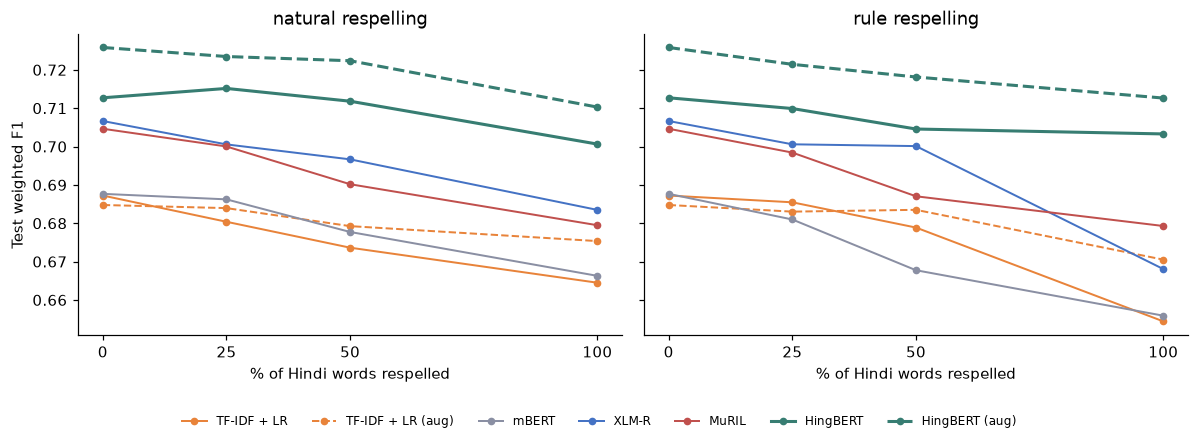

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
levels = [0, 25, 50, 100]
style = {"hingbert": ("#377D72", "-"), "hingbert_aug": ("#377D72", "--"), "tfidf_lr": ("#E8833A", "-"),
         "tfidf_lr_aug": ("#E8833A", "--"), "mbert": ("#8A8FA3", "-"), "xlmr": ("#4472C4", "-"), "muril": ("#C0504D", "-")}
for ax, mode in zip(axes, ["natural", "rule"]):
    for m in order:
        vals = f1.loc[NAMES[m], ["clean"] + [f"{mode} {l}%" for l in levels[1:]]].values
        c, ls = style[m]
        ax.plot(levels, vals, ls, color=c, marker="o", ms=4, lw=2 if "hingbert" in m else 1.3, label=NAMES[m])
    ax.set_title(f"{mode} respelling"); ax.set_xlabel("% of Hindi words respelled"); ax.set_xticks(levels)
axes[0].set_ylabel("Test weighted F1")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=len(l), fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.savefig(FIG_DIR / "05_robustness_f1.png"); plt.show()

### Augmented vs plain HingBERT (3 seeds each)

The key test: is the drop at 100 % respelling smaller with augmentation, and by more than the seed-to-seed noise?

In [10]:
def per_seed(m):
    t = res[res.model == m].pivot_table(index="seed", columns="set", values="wF1")
    return t[SETS], (t[SETS[1:]].sub(t["clean"], axis=0) * 100)

rows = []
for m in ["hingbert", "hingbert_aug", "tfidf_lr", "tfidf_lr_aug"]:
    if m not in set(res.model):
        continue
    t, d = per_seed(m)
    for k in ["clean", "natural 100%", "rule 100%"]:
        rows.append({"model": NAMES[m], "metric": f"wF1 {k}", "mean": t[k].mean(), "std": t[k].std() if len(t) > 1 else 0})
    for k in ["natural 100%", "rule 100%"]:
        rows.append({"model": NAMES[m], "metric": f"drop {k} (pts)", "mean": d[k].mean(), "std": d[k].std() if len(d) > 1 else 0})
cmp = pd.DataFrame(rows)
cmp["mean ± std"] = cmp["mean"].map("{:.4f}".format) + " ± " + cmp["std"].map("{:.4f}".format)
display(cmp.pivot(index="metric", columns="model", values="mean ± std"))

model,HingBERT,HingBERT (aug),TF-IDF + LR,TF-IDF + LR (aug)
metric,,,,
drop natural 100% (pts),-1.2070 ± 0.3959,-1.5543 ± 0.8003,-2.2730 ± 0.0000,-0.9411 ± 0.0000
drop rule 100% (pts),-0.9421 ± 0.5708,-1.3191 ± 0.4076,-3.2804 ± 0.0000,-1.4244 ± 0.0000
wF1 clean,0.7127 ± 0.0027,0.7258 ± 0.0071,0.6872 ± 0.0000,0.6848 ± 0.0000
wF1 natural 100%,0.7006 ± 0.0029,0.7103 ± 0.0125,0.6645 ± 0.0000,0.6753 ± 0.0000
wF1 rule 100%,0.7033 ± 0.0043,0.7126 ± 0.0112,0.6544 ± 0.0000,0.6705 ± 0.0000


## 7. Trust under noise: does confidence stay honest on misspelled tweets?

ECE on each set, before and after the temperature fitted on **clean** validation (as in notebook 04).

In [11]:
ece = res.groupby(["model", "set"])[["ECE", "ECE after T"]].mean().unstack()
for col in ["ECE", "ECE after T"]:
    t = ece[col][SETS].loc[order]; t.index = [NAMES[m] for m in order]
    print(col); display(t.round(4))

ECE


set,clean,natural 25%,natural 50%,natural 100%,rule 25%,rule 50%,rule 100%
TF-IDF + LR,0.0732,0.0789,0.0752,0.0831,0.0792,0.0786,0.0698
TF-IDF + LR (aug),0.0715,0.0743,0.0727,0.0799,0.0750,0.0807,0.0791
mBERT,0.0332,0.0303,0.0363,0.0425,0.0332,0.0443,0.0478
XLM-R,0.0406,0.0433,0.0457,0.0445,0.0343,0.0349,0.0544
MuRIL,0.0326,0.0313,0.0421,0.0480,0.0337,0.0429,0.0494
HingBERT,0.1047,0.1009,0.1062,0.1172,0.1058,0.1140,0.1125
HingBERT (aug),0.0560,0.0586,0.0579,0.0695,0.0615,0.0636,0.0714


ECE after T


set,clean,natural 25%,natural 50%,natural 100%,rule 25%,rule 50%,rule 100%
TF-IDF + LR,0.0605,0.0654,0.0608,0.0691,0.0653,0.0641,0.0562
TF-IDF + LR (aug),0.0578,0.0598,0.0584,0.0645,0.0606,0.0654,0.0639
mBERT,0.0565,0.0560,0.0520,0.0476,0.0518,0.0424,0.0385
XLM-R,0.0630,0.0622,0.0626,0.0516,0.0607,0.0632,0.0593
MuRIL,0.0610,0.0618,0.0526,0.0427,0.0573,0.0522,0.0436
HingBERT,0.0490,0.0494,0.0481,0.0472,0.0539,0.0476,0.0394
HingBERT (aug),0.0492,0.0513,0.0532,0.0476,0.0477,0.0445,0.0450


## 8. Save results

In [12]:
out = ROOT / "results"
res.to_csv(out / "05_robust_runs.csv", index=False)
f1.to_csv(out / "05_robust_f1.csv"); drop.to_csv(out / "05_robust_drop.csv")
cmp.to_csv(out / "05_aug_vs_plain.csv", index=False)
print("saved:", *sorted(p.name for p in out.glob("05_*")), sep="\n  ")

saved:
  05_aug_vs_plain.csv
  05_robust_drop.csv
  05_robust_f1.csv
  05_robust_runs.csv


## Takeaways

* **Spelling variation hurts every model, but by very different amounts.** At 100 % rule respelling: XLM-R −3.9, TF-IDF −3.3, mBERT −3.2, MuRIL −2.5, but **HingBERT only −0.9** F1 points. Pre-training on Hinglish tweets already makes HingBERT the most robust model by far.
* **For TF-IDF, augmentation works as planned:** it **more than halves the drop** (natural −2.3 → −0.9, rule −3.3 → −1.4) and costs only 0.2 points on clean tweets. It also helps on rule noise it never saw in training.
* **For HingBERT, augmentation does *not* shrink the drop** (natural −1.2 ± 0.4 → −1.6 ± 0.8; rule −0.9 ± 0.6 → −1.3 ± 0.4; within seed noise). HingBERT was already robust, so there was little drop left to remove.
* **But augmented HingBERT is the best model on every test set,** clean or respelled: clean 0.726 vs 0.713 (all 3 augmented seeds beat all 3 plain ones), natural 100 % 0.710 vs 0.701, rule 100 % 0.713 vs 0.703. The extra spelling variety works as a regulariser.
* **Augmentation also halves HingBERT's overconfidence:** ECE before scaling 0.105 → **0.056**, and it stays lower on every respelled set. After temperature scaling both are ≈ 0.05. Calibration holds up under respelling for all transformers.

**Decision:** the **spelling-augmented HingBERT** (best on val: seed 43, `runs_robust/aug/hingbert/seed43/model`) replaces plain HingBERT as the **teacher for the Efficient study**. It is more accurate, at least as robust and better calibrated. The compressed student will be checked on these same 7 test sets.